# Libraries

In [ ]:
!pip install ultralytics
!pip install scikit-learn
!pip install opencv-python matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 32.4 MB/s eta 0:00:00


In [ ]:
import json
import os
import shutil
from sklearn.model_selection import train_test_split
from ultralytics import YOLO
import cv2
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
from google.colab import files



# GARMI V1 · Trench segmentation with YOLOv8-seg

In [ ]:
# --- Colab: mount Drive
from google.colab import drive
drive.mount('/content/drive')

# --- PATHS FOLLOWING THE DRIVE FOLDER STRUCTURE ---
BASE_DIR = "/content/drive/MyDrive/ZANJAS_GARMI"

coco_json = f"{BASE_DIR}/annotations/instances_default.json"
source_images = f"{BASE_DIR}/images/default"          # folder with all the images
yolov8_seg_dataset_root = f"{BASE_DIR}/yolo_seg_dataset"  # output (will be created)

print("COCO JSON:", coco_json)
print("IMÁGENES :", source_images)
print("SALIDA   :", yolov8_seg_dataset_root)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
COCO JSON: /content/drive/MyDrive/ZANJAS_GARMI/annotations/instances_default.json
IMÁGENES : /content/drive/MyDrive/ZANJAS_GARMI/images/default
SALIDA   : /content/drive/MyDrive/ZANJAS_GARMI/yolo_seg_dataset


## COCO dataset preparation for YOLOv8-seg

In [ ]:
import os, json, shutil, logging
from collections import defaultdict
from sklearn.model_selection import train_test_split

logging.basicConfig(level=logging.INFO, format="%(levelname)s: %(message)s")

def _polygon_area_norm(points_xy):
    if len(points_xy) < 6:
        return 0.0
    xs = points_xy[0::2]
    ys = points_xy[1::2]
    n = len(xs)
    area = 0.0
    for i in range(n):
        j = (i + 1) % n
        area += xs[i] * ys[j] - xs[j] * ys[i]
    return abs(area) * 0.5

def _normalize_and_clip(segment, img_w, img_h):
    norm = []
    if len(segment) % 2 != 0:
        segment = segment[:-1]
    for i in range(0, len(segment), 2):
        x = segment[i] / float(img_w)
        y = segment[i+1] / float(img_h)
        x = 0.0 if x < 0 else (1.0 if x > 1 else x)
        y = 0.0 if y < 0 else (1.0 if y > 1 else y)
        norm.extend([round(x, 6), round(y, 6)])
    return norm

def convert_coco_segmentation_to_yolo_txt(coco_json_path, images_dir, output_labels_dir, class_id_map,
                                          min_area_norm=1e-6, log_every=2000):
    """
    COCO (polygons) -> YOLOv8-seg.
    One line per instance: <class_id> x1 y1 x2 y2 ... (0-1). No bbox.
    Multi-polygon: segments are concatenated on the same line.
    Empty .txt if the image has no instances.
    """
    os.makedirs(output_labels_dir, exist_ok=True)

    with open(coco_json_path, "r", encoding="utf-8") as f:
        coco = json.load(f)

    images = coco.get("images", [])
    annotations = coco.get("annotations", [])
    # remove old labels
    for fname in os.listdir(output_labels_dir):
        if fname.endswith(".txt"):
            os.remove(os.path.join(output_labels_dir, fname))

    anns_by_img = defaultdict(list)
    for ann in annotations:
        anns_by_img[ann["image_id"]].append(ann)

    skipped_unmapped = skipped_rle = skipped_too_small = 0

    for k, img in enumerate(images, 1):
        img_id = img["id"]
        w = img["width"]
        h = img["height"]
        base = os.path.splitext(img["file_name"])[0]
        out_txt = os.path.join(output_labels_dir, f"{base}.txt")

        lines = []
        for ann in anns_by_img.get(img_id, []):
            coco_cat = ann.get("category_id")
            yolo_cls = class_id_map.get(coco_cat, None)
            if yolo_cls is None:
                skipped_unmapped += 1
                continue

            seg = ann.get("segmentation")
            if isinstance(seg, dict) or ann.get("iscrowd", 0) == 1:
                skipped_rle += 1
                continue
            if not isinstance(seg, list) or len(seg) == 0:
                continue

            parts = [str(yolo_cls)]
            valid = False
            for segment in seg:
                if not isinstance(segment, list) or len(segment) < 6:
                    continue
                norm = _normalize_and_clip(segment, w, h)
                if len(norm) < 6 or len(norm) % 2 != 0:
                    continue
                if _polygon_area_norm(norm) < min_area_norm:
                    skipped_too_small += 1
                    continue
                parts.extend([f"{v:.6f}" if isinstance(v, float) else f"{v:.6f}" for v in norm])
                valid = True
            if valid and len(parts) > 1:
                lines.append(" ".join(parts))

        with open(out_txt, "w", encoding="utf-8") as f:
            if lines:
                f.write("\n".join(lines))

        if k % log_every == 0:
            logging.info(f"Procesadas {k}/{len(images)} imágenes...")

    if skipped_unmapped:
        logging.warning(f"category_id no mapeado (omitido): {skipped_unmapped}")
    if skipped_rle:
        logging.warning(f"RLE/iscrowd omitidos: {skipped_rle}")
    if skipped_too_small:
        logging.warning(f"Segmentos descartados por área mínima: {skipped_too_small}")

    logging.info(f"Labels YOLO generados en: {output_labels_dir}")

def prepare_coco_dataset_for_yolov8_seg(coco_json_path, img_source_dir, yolov8_dataset_root):
    """
    Build the YOLOv8-seg structure (train/val/test) from COCO (CVAT):
      - 80/10/10 split (reproducible)
      - Copy images
      - Convert annotations to .txt
      - Write data.yaml
    """
    os.makedirs(os.path.join(yolov8_seg_dataset_root, "images", "train"), exist_ok=True)
    os.makedirs(os.path.join(yolov8_seg_dataset_root, "images", "val"), exist_ok=True)
    os.makedirs(os.path.join(yolov8_seg_dataset_root, "images", "test"), exist_ok=True)
    os.makedirs(os.path.join(yolov8_seg_dataset_root, "annotations"), exist_ok=True)
    os.makedirs(os.path.join(yolov8_seg_dataset_root, "labels", "train"), exist_ok=True)
    os.makedirs(os.path.join(yolov8_seg_dataset_root, "labels", "val"), exist_ok=True)
    os.makedirs(os.path.join(yolov8_seg_dataset_root, "labels", "test"), exist_ok=True)

    with open(coco_json_path, "r", encoding="utf-8") as f:
        coco = json.load(f)

    images = coco["images"]
    annotations = coco["annotations"]
    categories = coco["categories"]

    # stable COCO -> YOLO (0-based) mapping
    sorted_cats = sorted(categories, key=lambda c: c["id"])
    category_id_to_yolo_id = {cat["id"]: i for i, cat in enumerate(sorted_cats)}
    class_names = [cat["name"] for cat in sorted_cats]
    logging.info(f"Map COCO->YOLO: {category_id_to_yolo_id}")
    logging.info(f"Clases: {class_names}")

    image_filenames = [img["file_name"] for img in images]
    train_filenames, temp_filenames = train_test_split(image_filenames, test_size=0.2, random_state=42)
    val_filenames, test_filenames = train_test_split(temp_filenames, test_size=0.5, random_state=42)

    def _subset(images_all, anns_all, filenames, subset_name):
        subset_images = [img for img in images_all if img["file_name"] in filenames]
        subset_ids = {img["id"] for img in subset_images}
        subset_annotations = [ann for ann in anns_all if ann["image_id"] in subset_ids]

        subset_coco = {
            "images": subset_images,
            "annotations": subset_annotations,
            "categories": categories  # original ones (category_id left untouched)
        }

        out_json = os.path.join(yolov8_seg_dataset_root, "annotations", f"{subset_name}_annotations.json")
        with open(out_json, "w", encoding="utf-8") as f:
            json.dump(subset_coco, f, ensure_ascii=False, indent=2)
        logging.info(f"COCO {subset_name}: {len(subset_images)} imágenes, {len(subset_annotations)} anotaciones -> {out_json}")

        # copy images
        dst_img_dir = os.path.join(yolov8_seg_dataset_root, "images", subset_name)
        for img in subset_images:
            src = os.path.join(img_source_dir, img["file_name"])
            dst = os.path.join(dst_img_dir, img["file_name"])
            if not os.path.exists(src):
                logging.warning(f"No se encontró la imagen: {src}")
                continue
            shutil.copy(src, dst)

        # convert to YOLO
        convert_coco_segmentation_to_yolo_txt(
            coco_json_path=out_json,
            images_dir=dst_img_dir,
            output_labels_dir=os.path.join(yolov8_seg_dataset_root, "labels", subset_name),
            class_id_map=category_id_to_yolo_id
        )

    _subset(images, annotations, train_filenames, "train")
    _subset(images, annotations, val_filenames, "val")
    _subset(images, annotations, test_filenames, "test")

    import json as _json
    names_literal = _json.dumps(class_names, ensure_ascii=False)
    data_yaml = (
        f"# data.yaml para YOLOv8-seg\n"
        f"train: {os.path.join(yolov8_seg_dataset_root, 'images', 'train')}\n"
        f"val: {os.path.join(yolov8_seg_dataset_root, 'images', 'val')}\n"
        f"test: {os.path.join(yolov8_seg_dataset_root, 'images', 'test')}\n\n"
        f"nc: {len(class_names)}\n"
        f"names: {names_literal}\n"
    )
    yaml_path = os.path.join(yolov8_seg_dataset_root, "data.yaml")
    with open(yaml_path, "w", encoding="utf-8") as f:
        f.write(data_yaml)
    logging.info(f"data.yaml escrito en: {yaml_path}")


In [ ]:
prepare_coco_dataset_for_yolov8_seg(
    coco_json_path=coco_json,
    img_source_dir=source_images,
    yolov8_dataset_root=yolov8_seg_dataset_root
)


In [ ]:
import os, glob, collections

root = yolov8_seg_dataset_root
report = {}

def parse_labels(lbl_path):
    lines = open(lbl_path, 'r', encoding='utf-8').read().strip().splitlines()
    classes = []
    for ln in lines:
        if not ln.strip():
            continue
        cls = int(ln.split()[0])
        classes.append(cls)
    return classes

for split in ['train','val','test']:
    img_dir = os.path.join(root, 'images', split)
    lbl_dir = os.path.join(root, 'labels', split)
    imgs = sorted([p for p in glob.glob(os.path.join(img_dir, '*'))
                   if os.path.splitext(p)[1].lower() in {'.jpg','.jpeg','.png','.tif','.tiff'}])
    lbls = sorted(glob.glob(os.path.join(lbl_dir, '*.txt')))
    img_bases = {os.path.splitext(os.path.basename(p))[0] for p in imgs}
    lbl_bases = {os.path.splitext(os.path.basename(p))[0] for p in lbls}
    missing_lbl = img_bases - lbl_bases
    extra_lbl = lbl_bases - img_bases

    empty_txt = 0
    class_counts = collections.Counter()
    for p in lbls:
        txt = open(p, 'r', encoding='utf-8').read().strip()
        if txt == '':
            empty_txt += 1
        else:
            for c in parse_labels(p):
                class_counts[c] += 1

    report[split] = dict(
        n_images=len(imgs),
        n_labels=len(lbls),
        missing_labels=len(missing_lbl),
        extra_labels=len(extra_lbl),
        empty_txt=empty_txt,
        class_counts=dict(class_counts)
    )

report


{'train': {'n_images': 44,
  'n_labels': 44,
  'missing_labels': 0,
  'extra_labels': 0,
  'empty_txt': 34,
  'class_counts': {5: 33, 16: 11, 7: 31, 13: 28, 10: 19, 11: 10, 15: 2}},
 'val': {'n_images': 6,
  'n_labels': 6,
  'missing_labels': 0,
  'extra_labels': 0,
  'empty_txt': 4,
  'class_counts': {5: 5, 7: 3, 10: 3, 13: 4}},
 'test': {'n_images': 6,
  'n_labels': 6,
  'missing_labels': 0,
  'extra_labels': 0,
  'empty_txt': 4,
  'class_counts': {16: 8, 10: 2, 7: 27, 5: 1}}}

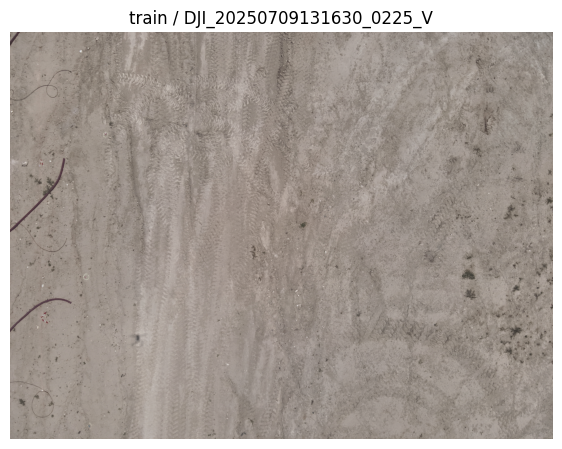

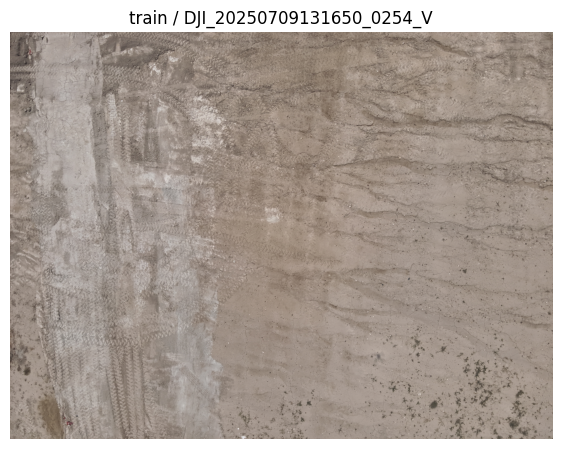

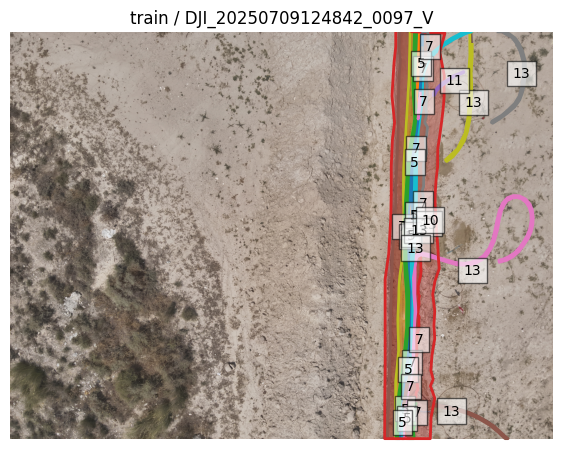

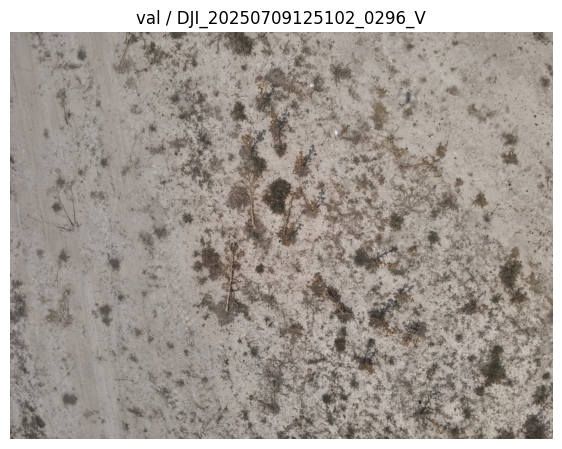

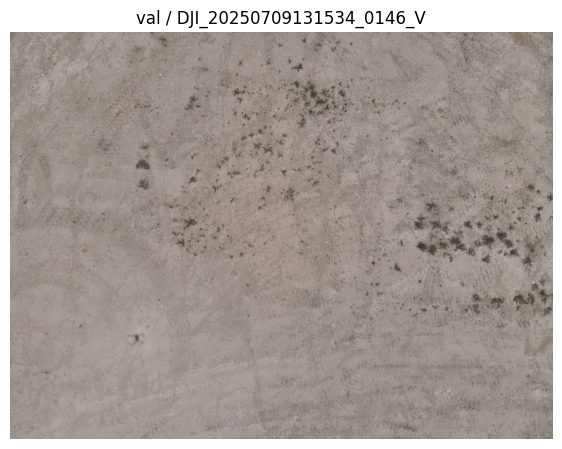

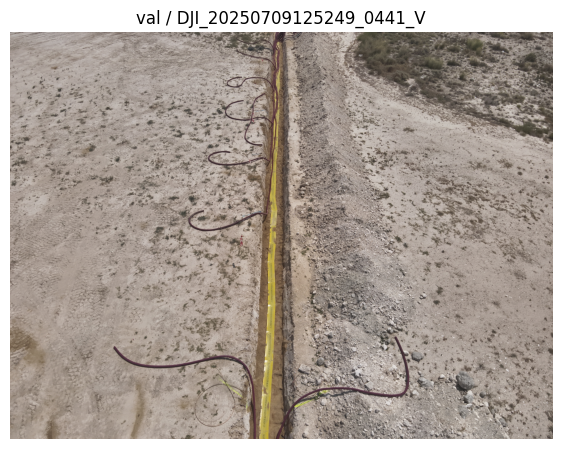

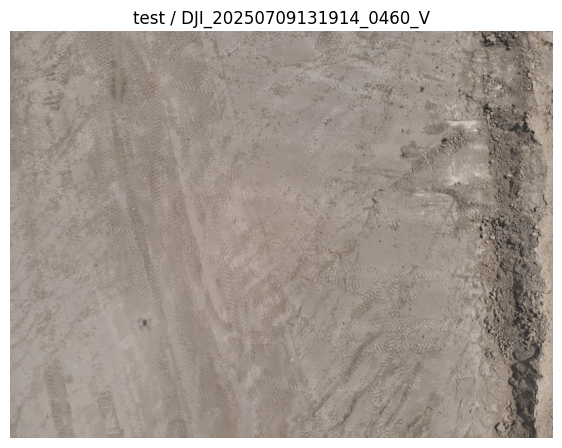

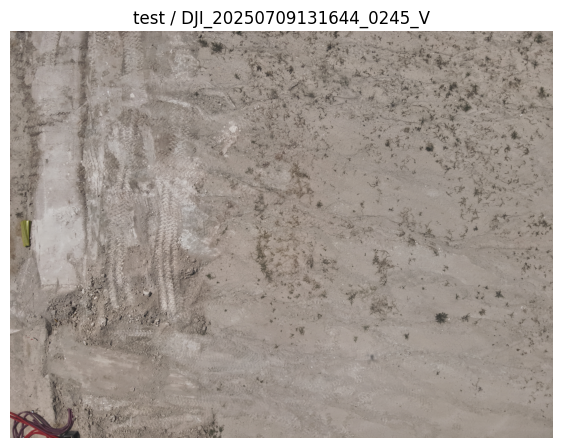

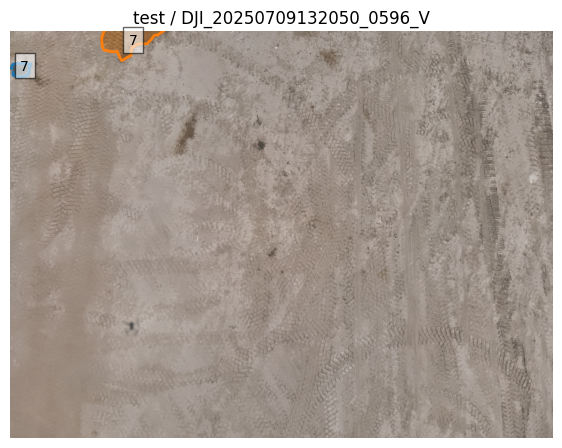

In [ ]:
import random, matplotlib.pyplot as plt
from PIL import Image
import numpy as np

def draw_yolo_seg(img_path, txt_path, title=None):
    im = np.array(Image.open(img_path).convert('RGB'))
    H, W = im.shape[:2]
    fig, ax = plt.subplots(figsize=(7,7))
    ax.imshow(im)
    if os.path.exists(txt_path):
        for line in open(txt_path, 'r', encoding='utf-8'):
            line = line.strip()
            if not line:
                continue
            parts = line.split()
            cls = int(parts[0])
            coords = list(map(float, parts[1:]))
            xs = np.array(coords[0::2]) * W
            ys = np.array(coords[1::2]) * H
            ax.plot(xs, ys, linewidth=2)
            ax.fill(xs, ys, alpha=0.25)
            ax.text(xs.mean(), ys.mean(), f"{cls}", fontsize=10,
                    bbox=dict(facecolor='white', alpha=0.6))
    ax.set_axis_off()
    if title:
        ax.set_title(title)
    plt.show()

for split in ['train','val','test']:
    img_dir = os.path.join(yolov8_seg_dataset_root, 'images', split)
    lbl_dir = os.path.join(yolov8_seg_dataset_root, 'labels', split)
    imgs = [p for p in glob.glob(os.path.join(img_dir, '*'))
            if os.path.splitext(p)[1].lower() in {'.jpg','.jpeg','.png','.tif','.tiff'}]
    if not imgs:
        continue
    sample = random.sample(imgs, min(3, len(imgs)))
    for ip in sample:
        base = os.path.splitext(os.path.basename(ip))[0]
        tp = os.path.join(lbl_dir, base + '.txt')
        draw_yolo_seg(ip, tp, title=f"{split} / {base}")


## Model training

In [ ]:
!pip -q install ultralytics
from ultralytics import YOLO
import os

data_yaml = os.path.join(yolov8_seg_dataset_root, 'data.yaml')
model = YOLO('yolov8n-seg.pt')  # try s/m for more capacity

results = model.train(
    data=data_yaml,
    imgsz=1024,
    epochs=150,
    patience=30,
    batch=8,
    lr0=0.01,
    lrf=0.01,
    cos_lr=True,
    hsv_h=0.015, hsv_s=0.7, hsv_v=0.4,
    degrees=0.0,
    translate=0.05,
    scale=0.5,
    shear=0.0,
    flipud=0.0,
    fliplr=0.5,
    mosaic=0.7,
    workers=2
)

print("\nEntrenamiento completado.")



Ultralytics 8.3.191 🚀 Python-3.12.11 torch-2.8.0+cu126 CUDA:0 (Tesla T4, 15095MiB)
engine/trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/content/drive/MyDrive/ZANJAS_GARMI/yolo_seg_dataset/data.yaml, degrees=0.0, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=150, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=1024, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n-seg.pt, momentum=0.937, mosaic=0.7, multi_scale=False, name=train, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, overlap_mask=True, patience=30, perspective=0

## Save the trained model to Google Drive

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import shutil, os

# Path to the trained model
best_model = "runs/segment/train/weights/best.pt"

# Destination path in Drive
save_path = "/content/drive/MyDrive/ZANJAS_GARMI/modelo_zanjas_best.pt"

# Copy
os.makedirs(os.path.dirname(save_path), exist_ok=True)
shutil.copy(best_model, save_path)

print(f"✅ Modelo guardado en: {save_path}")




Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
✅ Modelo guardado en: /content/drive/MyDrive/ZANJAS_GARMI/modelo_zanjas_best.pt


## Inference and results visualization

In [ ]:
best = model.ckpt_path  # or load runs/segment/*/weights/best.pt explicitly
val_res = model.val(data=data_yaml, imgsz=1024)

import glob
sample_imgs = glob.glob(os.path.join(yolov8_seg_dataset_root, 'images', 'val', '*'))[:10]
pred = model.predict(source=sample_imgs, imgsz=1024, conf=0.25, save=True)
pred



Ultralytics 8.3.191 🚀 Python-3.12.11 torch-2.8.0+cu126 CUDA:0 (Tesla T4, 15095MiB)
YOLOv8n-seg summary (fused): 85 layers, 3,261,379 parameters, 0 gradients, 11.4 GFLOPs
val: Fast image access ✅ (ping: 0.4±0.2 ms, read: 503.5±47.9 MB/s, size: 6037.6 KB)
val: Scanning /content/drive/MyDrive/ZANJAS_GARMI/yolo_seg_dataset/labels/val.cache... 6 images, 4 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 6/6 5849.8it/s 0.0s
WARNING ⚠️ Limiting validation plots to first 50 items per image for speed...
WARNING ⚠️ Limiting validation plots to first 50 items per image for speed...
WARNING ⚠️ Limiting validation plots to first 50 items per image for speed...
WARNING ⚠️ Limiting validation plots to first 50 items per image for speed...
WARNING ⚠️ Limiting validation plots to first 50 items per image for speed...
WARNING ⚠️ Limiting validation plots to first 50 items per image for speed...
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      m

[ultralytics.engine.results.Results object with attributes:
 
 boxes: ultralytics.engine.results.Boxes object
 keypoints: None
 masks: None
 names: {0: 'Poste', 1: 'Puerta de acceso', 2: 'Placa Avifauna', 3: 'Malla valla', 4: 'Paso de fauna', 5: 'Placas protección zanja', 6: 'Arquetas', 7: 'Limo', 8: 'Cable MT', 9: 'Contenedor', 10: 'Zanja', 11: 'Spray guía zanja', 12: 'Bobinas', 13: 'Tubo corrugado', 14: 'cable de cobre desnudo', 15: 'cinta amarilla  de riesgo electrico', 16: 'cable BT'}
 obb: None
 orig_img: array([[[ 65,  81,  93],
         [ 77,  93, 105],
         [ 90, 106, 118],
         ...,
         [ 61,  61,  75],
         [ 65,  59,  78],
         [ 63,  57,  76]],
 
        [[ 64,  80,  92],
         [ 75,  91, 103],
         [ 88, 104, 116],
         ...,
         [ 61,  61,  75],
         [ 60,  57,  73],
         [ 59,  53,  72]],
 
        [[ 72,  87,  96],
         [ 75,  90,  99],
         [ 78,  93, 102],
         ...,
         [ 66,  66,  80],
         [ 65,  62,  

## Inference on sample images

Imágenes de prueba: ['/content/drive/MyDrive/ZANJAS_GARMI/yolo_seg_dataset/images/val/DJI_20250709124802_0039_V.jpg', '/content/drive/MyDrive/ZANJAS_GARMI/yolo_seg_dataset/images/val/DJI_20250709124919_0149_V.jpg', '/content/drive/MyDrive/ZANJAS_GARMI/yolo_seg_dataset/images/val/DJI_20250709125102_0296_V.jpg', '/content/drive/MyDrive/ZANJAS_GARMI/yolo_seg_dataset/images/val/DJI_20250709125249_0441_V.jpg', '/content/drive/MyDrive/ZANJAS_GARMI/yolo_seg_dataset/images/val/DJI_20250709131534_0146_V.jpg']

0: 768x1024 (no detections), 13.5ms
1: 768x1024 (no detections), 13.5ms
2: 768x1024 (no detections), 13.5ms
3: 768x1024 (no detections), 13.5ms
4: 768x1024 (no detections), 13.5ms
Speed: 8.7ms preprocess, 13.5ms inference, 1.1ms postprocess per image at shape (1, 3, 768, 1024)
Results saved to runs/segment/predict6
✅ Inferencias guardadas en: runs/segment/predict6


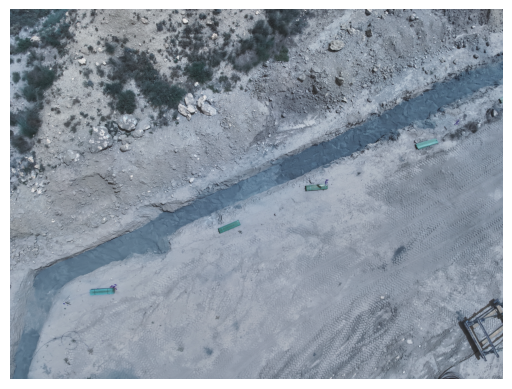

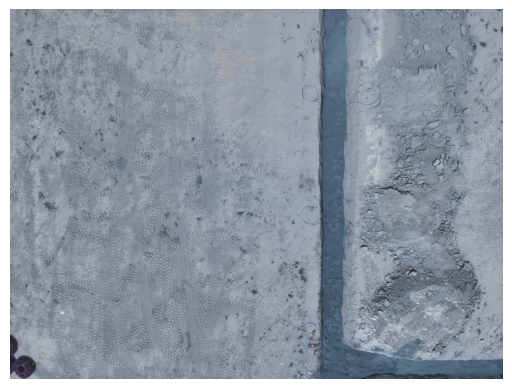

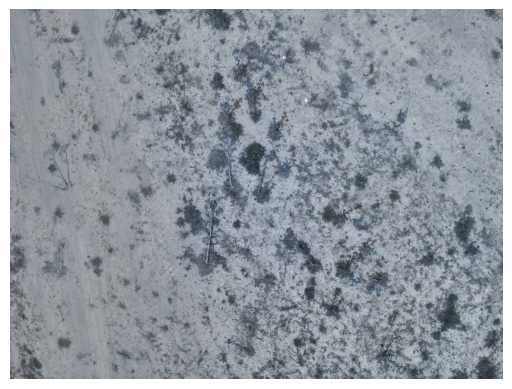

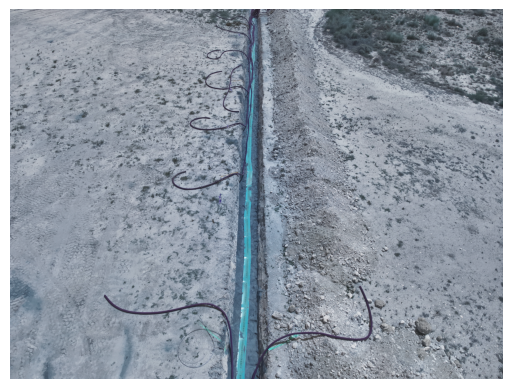

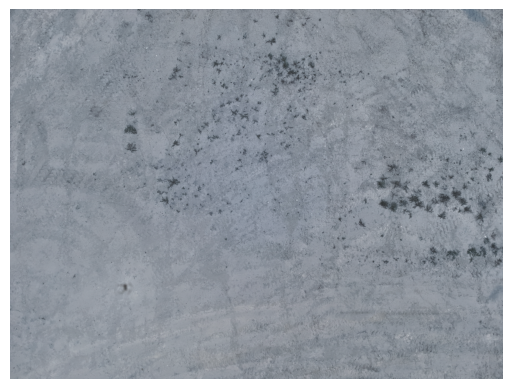

In [ ]:
from ultralytics import YOLO
import glob, os

# === 1) Load trained model ===
model_path = "/content/drive/MyDrive/ZANJAS_GARMI/modelo_zanjas_best.pt"
model = YOLO(model_path)

# === 2) Test images ===
val_dir = "/content/drive/MyDrive/ZANJAS_GARMI/yolo_seg_dataset/images/val"
sample_imgs = glob.glob(os.path.join(val_dir, "*"))[:5]
print("Imágenes de prueba:", sample_imgs)

# === 3) Inference ===
results = model.predict(
    source=sample_imgs,
    imgsz=1024,
    conf=0.25,
    save=True
)

# === 4) Show output folder ===
# Each Results object has a save_dir attribute
if results:
    print("✅ Inferencias guardadas en:", results[0].save_dir)
else:
    print("⚠️ No hubo resultados.")

# === 5) (Optional) Show inline in the notebook ===
import matplotlib.pyplot as plt
for r in results:
    plt.imshow(r.plot())  # plot draws the prediction on the image
    plt.axis("off")
    plt.show()
